# TurboVLA: полный эвал и проверка VRAM на RTX 4090

## Цель и краткий результат
Здесь читаются сохранённые результаты полного прогона на D0/D1/D2/H1/H2 и независимого измерения памяти. Значения строятся из JSON, а не вручную. Все пять задач входили в обучение опубликованного checkpoint; H1/H2 являются held-out только для вариантов π₀ из исходного эксперимента.

Полные результаты: `results/reference_n50` (основное сопоставление с seed-протоколом π₀) и, если выполнен, `results/official_n50` (стандартные initial states). Пять задач не заменяют полный четырёх-suite benchmark статьи; среднее по нашим пяти нельзя выдавать за заявленные 97,6%.

Источники: [статья v3, приложение B.2](https://arxiv.org/pdf/2607.27205v3), [TurboVLA](https://github.com/H-EmbodVis/TurboVLA), [веса и сведения об обучении](https://huggingface.co/H-EmbodVis/TurboVLA), [π₀-протокол](https://github.com/qrvmil/maniskill_myws/blob/exp/pi0-multitask-sft-generalization/src/maniskill_myws/pld/multitask_protocol.py).


## Подготовка
Открыть в kernel TurboVLA LIBERO; этот ноутбук читает результаты на CPU. Новое измерение VRAM запускается отдельным процессом из `.venv`, чтобы память старого Jupyter kernel не попала в оценку. Сначала завершите GPU kernel первого ноутбука.


In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Video, Markdown
ROOT = Path.cwd()
sys.path.insert(0,str(ROOT))
from eval_utils import TASKS, summarize
plt.rcParams.update({"figure.figsize": (9,4), "font.size":11, "axes.spines.top":False, "axes.spines.right":False})
RESULTS = ROOT / "results"
PROTOCOLS = [name for name in ["reference_n50", "official_n50"] if (RESULTS / name / "complete.json").is_file()]
assert "reference_n50" in PROTOCOLS, "Сначала выполните полный run_eval.py"


## Метод

### 1. Что сравниваем
Один и тот же checkpoint и BF16, две камеры 256×256, BERT онлайн, chunk=12, open-loop=12. `reference`: seed 10000–10049, ten settling steps, MSAA off, горизонты 220/280; `official`: initial state index 0–49, seed 7 один раз на задачу (RNG-поток продолжается между эпизодами), Goal horizon=300. Это два разных распределения reset. У π₀ также был другой replan=5 и своя нормализация. Поэтому различие success rate нельзя приписывать только архитектуре или размеру SFT.

Реальный двухэпизодный smoke-тест D0 дал побайтовое совпадение всех действий нашего официального режима с неизменённым `vla_adapter.rollout._run_episode`; запись — `results/official_parity/upstream_action_parity.json`. Это проверка двух эпизодов одной задачи, не доказательство совпадения всех 2000 эпизодов авторов.

Успех проверяется симулятором; denominator включает все 50 завершённых эпизодов, timeout — failure. Wilson 95% CI оценивает биномиальную неопределённость внутри выбранного reset-распределения; это не разброс обучения модели. Между задачами веса одинаковые.


In [2]:
records=[]
for protocol in PROTOCOLS:
    for key in TASKS:
        rows=json.loads((RESULTS/protocol/key/"episodes.json").read_text())
        assert len(rows)==50 and len({r["seed"] for r in rows})==50
        summary=summarize(rows)
        saved=json.loads((RESULTS/protocol/key/"summary.json").read_text())
        assert summary==saved
        records.append(dict(protocol=protocol,task=key,**summary))
table=pd.DataFrame(records)
table["success_percent"]=table.success_rate*100
table["Wilson 95%, %"]=table.ci95.map(lambda ci: f"{ci[0]*100:.1f}–{ci[1]*100:.1f}")
display(table[["protocol","task","successes","episodes","success_percent","Wilson 95%, %","mean_steps"]].round(2))


,protocol,task,successes,episodes,success_percent,"Wilson 95%, %",mean_steps
0,reference_n50,D0,50,50,100.0,92.9–100.0,92.68
1,reference_n50,D1,45,50,90.0,78.6–95.7,105.12
2,reference_n50,D2,50,50,100.0,92.9–100.0,86.56
3,reference_n50,H1,50,50,100.0,92.9–100.0,103.82
4,reference_n50,H2,50,50,100.0,92.9–100.0,138.40
5,official_n50,D0,50,50,100.0,92.9–100.0,94.42
6,official_n50,D1,50,50,100.0,92.9–100.0,95.66
7,official_n50,D2,49,50,98.0,89.5–99.6,90.68
8,official_n50,H1,50,50,100.0,92.9–100.0,105.34
9,official_n50,H2,49,50,98.0,89.5–99.6,141.10


## Результаты

### 2. Успех по задачам
Столбики начинаются с нуля; вертикальные интервалы — Wilson 95%. Даже 50/50 не означает истинную вероятность ровно 100%. Mean ниже относится только к выбранным пяти задачам.


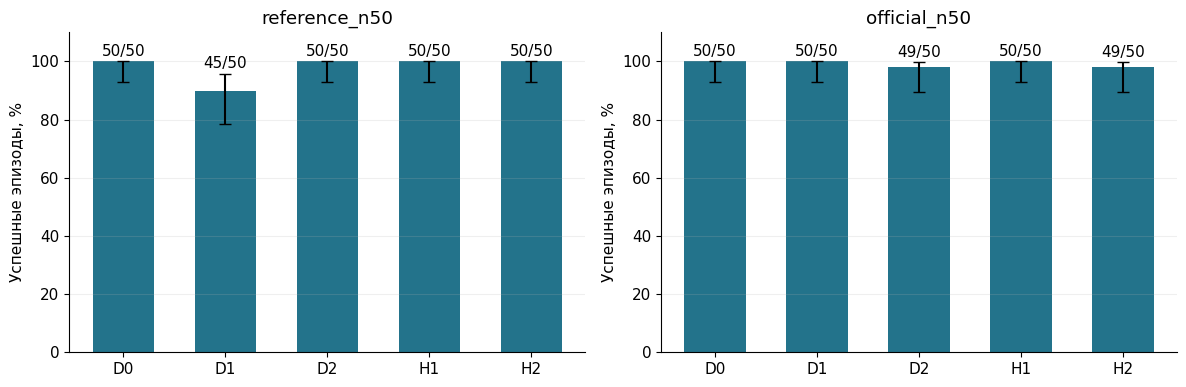

reference_n50 Среднее по пяти задачам: 98.0%
official_n50 Среднее по пяти задачам: 99.2%


In [3]:
fig,axes=plt.subplots(1,len(PROTOCOLS),figsize=(6*len(PROTOCOLS),4),squeeze=False)
for ax,protocol in zip(axes[0],PROTOCOLS):
    subset=table[table.protocol==protocol]
    values=subset.success_rate.to_numpy()*100
    ci=np.array(subset.ci95.tolist())*100
    ax.bar(subset.task,values,color="#23738b",width=.6)
    ax.errorbar(np.arange(len(values)),values,yerr=np.maximum(0,[values-ci[:,0],ci[:,1]-values]),fmt="none",color="black",capsize=4)
    for i,value in enumerate(values): ax.text(i,ci[i,1]+2,f"{int(subset.iloc[i].successes)}/50",ha="center")
    ax.set(ylim=(0,110),ylabel="Успешные эпизоды, %",title=protocol)
    ax.grid(axis="y",alpha=.2)
fig.tight_layout();display(fig);plt.close(fig)
for protocol in PROTOCOLS:
    subset=table[table.protocol==protocol]
    print(protocol, "Среднее по пяти задачам:",f"{subset.success_percent.mean():.1f}%")


### Исходные варианты π₀ рядом с TurboVLA
Ниже — **сохранённые** результаты A/B/C после 3001 обновления из вашего репозитория, не новые прогоны π₀. A обучался на D0, B на D0+D1, C на D0+D1+D2; TurboVLA обучался на всех 40 задачах. Для TurboVLA берём `reference_n50`, чтобы проверить физические reset по одинаковым seed. Из-за разных обучающих данных, preprocessing и replan это сравнение опубликованных систем, а не контролируемая оценка влияния одного метода SFT.

Исходные минимальные записи сохранены в `provenance/pi0/<variant>/<task>/episodes.json`; ревизия reference — в `provenance/source_revisions.json`. H1/H2 для A/B/C были held-out; для TurboVLA — seen.


In [4]:
comparison=[]
for variant,label in [("A","π₀ A: D0"),("B","π₀ B: D0+D1"),("C","π₀ C: D0+D1+D2")]:
    for key in TASKS:
        path=ROOT/"provenance/pi0"/variant/key/"episodes.json"
        rows=json.loads(path.read_text())
        assert len(rows)==50
        comparison.append(dict(model=label,task=key,success_percent=100*sum(r["success"] for r in rows)/50))
for _,row in table[table.protocol=="reference_n50"].iterrows():
    comparison.append(dict(model="TurboVLA: 40 задач",task=row.task,success_percent=row.success_percent))
comparison_table=pd.DataFrame(comparison).pivot(index="model",columns="task",values="success_percent")
display(comparison_table[["D0","D1","D2","H1","H2"]])


task,D0,D1,D2,H1,H2
model,,,,,
TurboVLA: 40 задач,100.0,90.0,100.0,100.0,100.0
π₀ A: D0,70.0,0.0,0.0,0.0,0.0
π₀ B: D0+D1,56.0,18.0,0.0,0.0,0.0
π₀ C: D0+D1+D2,42.0,38.0,62.0,0.0,0.0


### 3. Видео для всех задач
Все эпизоды обоих полных прогонов записаны в отдельную директорию. Ниже автоматически выбираем первый success и первый failure, если они есть. Отсутствие failure-видео при 50/50 обозначает отсутствие failures в выборке, а не ошибку сохранения. MP4 sidecar JSON содержит seed, длину и reset hash.


In [5]:
video_records=[]
for key in TASKS:
    rows=json.loads((RESULTS/"reference_n50"/key/"episodes.json").read_text())
    for outcome in [True,False]:
        candidates=[r for r in rows if r["success"]==outcome]
        if candidates:
            row=candidates[0]
            path=ROOT/row["video"]
            assert path.is_file()
            video_records.append(dict(task=key,outcome="success" if outcome else "failure",seed=row["seed"],path=str(path.relative_to(ROOT))))
display(pd.DataFrame(video_records))
if video_records:
    display(Video(str(ROOT/video_records[0]["path"]),embed=True,width=768))


,task,outcome,seed,path
0,D0,success,10000,results/reference_n50/videos/D0/episode_000.mp4
1,D1,success,10000,results/reference_n50/videos/D1/episode_000.mp4
2,D1,failure,10009,results/reference_n50/videos/D1/episode_009.mp4
3,D2,success,10000,results/reference_n50/videos/D2/episode_000.mp4
4,H1,success,10000,results/reference_n50/videos/H1/episode_000.mp4
5,H2,success,10000,results/reference_n50/videos/H2/episode_000.mp4


### 4. Проверка совпадения reset с исходным π₀-экспериментом
Одинаковые числа seed ещё не доказывают одинаковые физические состояния. Для каждого seed сравниваем SHA256 состояния после settling с сохранённым π₀ `reset_hash`, где исходные записи доступны. Это проверка физического reset, не побайтового совпадения изображений между разными GPU/рендерерами.


In [6]:
audit_path=RESULTS/"reference_reset_audit.json"
if audit_path.exists():
    reset_audit=json.loads(audit_path.read_text())
    display(pd.DataFrame(reset_audit["tasks"]).T)
    display(Markdown(reset_audit["interpretation"]))
else:
    display(Markdown("Проверка reset ещё не выполнена; нельзя называть эпизоды парными только по seed."))


,episodes,reference_covered,reset_hash_matches,reset_hash_mismatches,videos_verified
D0,50,50,50,0,50
D1,50,50,50,0,50
D2,50,50,50,0,50
H1,50,50,50,0,50
H2,50,50,50,0,50


Все 250 физических reset-состояний побайтово совпадают с исходным π₀-экспериментом по SHA256. Это позволяет сопоставлять исходы по seed; модели имеют разное обучающее покрытие и разные replan/preprocessing.

### 5. Что именно означает «<1 GB» в статье
В версии v3 заявлено **0,9 GiB**. GiB = 1024³ байт; GB = 10⁹ байт. Мы показываем обе единицы: расход чуть ниже 1 GiB может оказаться выше 1 GB.

В приложении B.2 память измеряется как `peak nvidia-smi − idle nvidia-smi` с момента запуска процесса, включая загрузку, 10 warmup и 50 timed inference. Batch=1. Симулятор и подготовка/перенос изображений исключены из измерения latency; output chunk остаётся на GPU. Поэтому `torch.memory_allocated()` само по себе не проверяет заявление статьи: оно не учитывает CUDA context и часть библиотечных буферов.

Наш parent-процесс не импортирует torch, запускает `nvidia-smi` каждые 50 ms **до старта** отдельного worker. Worker загружает всю модель и реальное сохранённое D0-наблюдение; BERT вычисляется онлайн. Без CPU offload, квантования, удаления модулей или кэша текста. На этой headless-машине проверяем также idle-память ≤32 MiB: внутри контейнера `nvidia-smi` иногда не показывает PID даже активного процесса. Нагрузка других GPU-процессов исключается перед запуском; sampling может пропустить очень короткий пик, поэтому дополнительно сохраняются PyTorch peak allocated/reserved. Полный rollout с EGL имеет дополнительную память рендеринга и измеряется отдельно.


In [7]:
vram_rows=[]
for precision in ["bf16","fp32"]:
    path=RESULTS/f"vram_{precision}"/"summary.json"
    if path.exists():
        measurement=json.loads(path.read_text())
        vram_rows.append({key:measurement[key] for key in ["precision","gpu","parameters","delta_gib","delta_gb","torch_peak_allocated_gib","torch_peak_reserved_gib","median_ms","p90_ms","sample_count","at_most_1_gib","at_most_1_gb"]})
assert vram_rows, "Запустите benchmark_vram.py"
vram=pd.DataFrame(vram_rows)
print("GPU:", vram.iloc[0].gpu, "| Parameters:", f"{vram.iloc[0].parameters:,}")
memory_columns=["precision", "delta_gib", "delta_gb",
                "torch_peak_allocated_gib", "torch_peak_reserved_gib"]
memory_labels={"delta_gib":"nvidia-smi, GiB", "delta_gb":"nvidia-smi, GB",
               "torch_peak_allocated_gib":"torch allocated, GiB",
               "torch_peak_reserved_gib":"torch reserved, GiB"}
display(vram[memory_columns].rename(columns=memory_labels).round(4))
display(vram[["precision","median_ms","p90_ms","sample_count",
              "at_most_1_gib","at_most_1_gb"]].round(3))
for row in vram_rows:
    display(Markdown(f"**{row['precision']}**: peak − idle = **{row['delta_gib']:.3f} GiB / {row['delta_gb']:.3f} GB**. Порог ≤1 GiB: {'выполнен' if row['at_most_1_gib'] else 'не выполнен'}; ≤1 GB: {'выполнен' if row['at_most_1_gb'] else 'не выполнен'}. Median policy forward: **{row['median_ms']:.2f} ms**."))


GPU: NVIDIA GeForce RTX 4090 | Parameters: 216,073,239


,precision,"nvidia-smi, GiB","nvidia-smi, GB","torch allocated, GiB","torch reserved, GiB"
0,bf16,0.9209,0.9888,0.4345,0.4473
1,fp32,1.3877,1.4900,0.8349,0.9141


,precision,median_ms,p90_ms,sample_count,at_most_1_gib,at_most_1_gb
0,bf16,31.797,31.996,163,True,True
1,fp32,36.566,36.899,175,False,False


**bf16**: peak − idle = **0.921 GiB / 0.989 GB**. Порог ≤1 GiB: выполнен; ≤1 GB: выполнен. Median policy forward: **31.80 ms**.

**fp32**: peak − idle = **1.388 GiB / 1.490 GB**. Порог ≤1 GiB: не выполнен; ≤1 GB: не выполнен. Median policy forward: **36.57 ms**.

### 6. Память во времени
Latency измеряет вычисление одного чанка, а не скорость полного цикла симулятора. В LIBERO контроллер обычно работает на 20 Hz, и 12-step open-loop означает новую командную последовательность примерно через 0,6 s симуляционного времени. Поэтому обратную величину latency нельзя выдавать за фактическую частоту closed-loop управления этого rollout.

Кривая охватывает загрузку и forward, а не только уже прогретую модель. Пунктиры — 1 GiB и 1 GB сверх исходного idle. FP32 — проверка чувствительности к precision; основной режим релиза BF16.


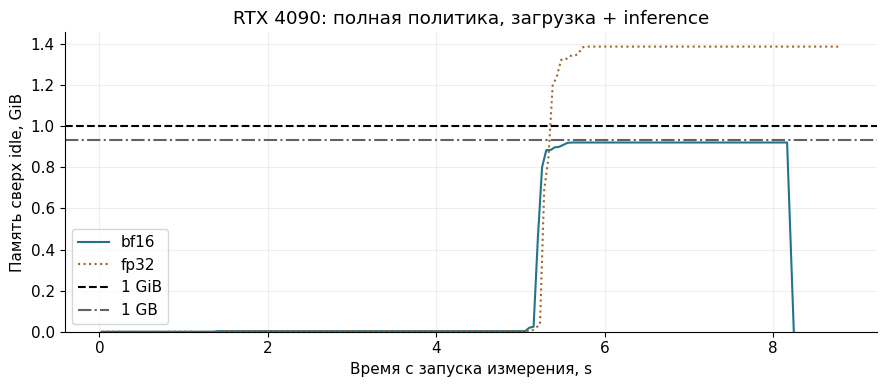

,delta_gib,delta_gb,sample_interval_ms,duration_s
0,1.4541,1.5613,100,1127.3285


Полный официальный эвал с LIBERO/EGL и видео: **1.454 GiB / 1.561 GB**. Память симулятора входит в эту величину; это отдельная граница измерения от policy-only VRAM статьи.

Повторная проверка BF16 после обоих эвалов: **0.921 GiB / 0.989 GB**, median **31.78 ms**. Raw samples и описание входного наблюдения сохранены отдельно.

In [8]:
fig,ax=plt.subplots(figsize=(9,4))
styles={"bf16":dict(color="#23738b",linestyle="-"),
        "fp32":dict(color="#a26722",linestyle=":")}
for precision in vram.precision:
    folder=RESULTS/f"vram_{precision}"
    samples=[json.loads(line) for line in (folder/"memory_samples.jsonl").read_text().splitlines()]
    idle=json.loads((folder/"summary.json").read_text())["idle_mib"]
    ax.plot([s["time_s"] for s in samples],[(s["used_mib"]-idle)/1024 for s in samples],label=precision,**styles[precision])
ax.axhline(1,color="black",linestyle="--",label="1 GiB")
ax.axhline(1e9/1024**3,color="#626262",linestyle="-.",label="1 GB")
ax.set(xlabel="Время с запуска измерения, s",ylabel="Память сверх idle, GiB",title="RTX 4090: полная политика, загрузка + inference")
ax.set_ylim(bottom=0);ax.legend();ax.grid(alpha=.2);fig.tight_layout();display(fig);plt.close(fig)
rollout_path=RESULTS/"rollout_memory.json"
if rollout_path.exists():
    rollout_memory=json.loads(rollout_path.read_text())
    display(pd.DataFrame([rollout_memory])[["delta_gib","delta_gb",
        "sample_interval_ms","duration_s"]].round(4))
    display(Markdown(
        f"Полный официальный эвал с LIBERO/EGL и видео: **{rollout_memory['delta_gib']:.3f} GiB / "
        f"{rollout_memory['delta_gb']:.3f} GB**. Память симулятора входит в эту величину; "
        "это отдельная граница измерения от policy-only VRAM статьи."))
recheck_path=RESULTS/"vram_bf16_recheck/summary.json"
if recheck_path.exists():
    recheck=json.loads(recheck_path.read_text())
    display(Markdown(
        f"Повторная проверка BF16 после обоих эвалов: **{recheck['delta_gib']:.3f} GiB / "
        f"{recheck['delta_gb']:.3f} GB**, median **{recheck['median_ms']:.2f} ms**. "
        "Raw samples и описание входного наблюдения сохранены отдельно."))


## Проверки и дальнейшая работа

### 7. Повторить самостоятельно
Эти команды запускаются из `turbovla_eval` в терминале; результаты пишутся в новую папку. Для VRAM предварительно завершите все GPU kernels и убедитесь `nvidia-smi`, что карта свободна.
```bash
.venv/bin/python run_eval.py --protocol reference --episodes 50 --tasks D0,D1,D2,H1,H2 --output results/my_reference_run
.venv/bin/python run_eval.py --protocol official --episodes 50 --tasks D0,D1,D2,H1,H2 --output results/my_official_run
.venv/bin/python benchmark_vram.py --precision bf16 --output results/my_vram_run
```
Или в первом ноутбуке выберите другую задачу, измените количество эпизодов и запустите Run All.

Вывод о VRAM относится к нашей измеренной реализации, версии библиотек, precision и sampling. Один прогон не доказывает универсальный предел для любого процесса/драйвера. Значения статьи и нашего прогона сравнивайте в **одинаковых единицах и границах измерения**. Результаты H1/H2 не подтверждают OOD-обобщение TurboVLA, поскольку модель видела их демонстрации при обучении.
